In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [2]:
torch.cuda.is_available()

False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cpu')

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))  # mean and std
])

In [6]:
# Load dataset
train_dataset = torchvision.datasets.MNIST(
    root= './data',
    train= True,
    download= True,
    transform= transform
)

test_dataset = torchvision.datasets.MNIST(
    root= './data',
    train= False,
    download= True,
    transform= transform
)

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:01<00:00, 7190665.91it/s] 


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 211081.92it/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:00<00:00, 1657530.79it/s]


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 2272248.18it/s]


Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw



The shape is :  torch.Size([1, 28, 28])


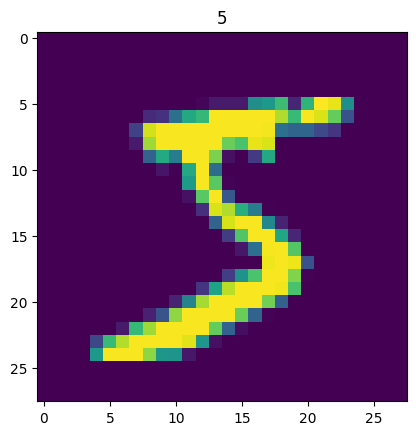

In [13]:
import matplotlib.pyplot as plt
image, label = train_dataset[0]
print("The shape is : ", image.shape)
plt.imshow(image.squeeze())
plt.title(label)
plt.show()

In [11]:
# Create data loaders

train_loader = DataLoader(
    dataset= train_dataset,
    batch_size= 64,
    shuffle= True
)


test_loader = DataLoader(
    dataset= test_dataset,
    batch_size= 1000,
    shuffle= False
)

In [15]:
print(28 * 28)

784


In [16]:
# Create a neural network

class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.flatten = nn.Flatten()
        self.layers= nn.Sequential(
            nn.Linear(in_features= 784, out_features= 128),   # 784 is the result of flatten() applied on image (2D ARRAY) of 28*28 when we appky fkatten it becomes a flat vector of 784 elements
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=10)
        )
        
        
    def forward(self, x):
        x = self.flatten(x)
        x = self.layers(x)
        return x
        

In [17]:
# setting the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Using {device}")

 Using cpu


In [ ]:
# Initialize model and move it to device

model = MNISTClassifier().to(device)
model

MNISTClassifier(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [20]:
# Loss and optimizer
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params= model.parameters(), lr= 0.001)

In [21]:
# Train Loop

def train_epoch(model, train_loader, loss_function, optimizer, device):
    model.train()
    running_loss= 0.0
    correct, total = 0, 0
    
    for batch_idx, (data, target) in enumerate(train_loader):
        
        # Data must be in the same device as the model
        data, target = data.to(device), target.to(device)
        
        # The general steps for training
        optimizer.zero_grad()
        output = model(data)
        loss = loss_function(output, target)
        loss.backward()
        optimizer.step()
        
        
        # Optional to track progress
        running_loss += loss.item()
        _, predicted = output.max(1)
        total+= target.size(0)
        correct+= predicted.eq(target).sum().item()
        
        
        # Print every 100 batches
        if batch_idx% 100 ==0 and batch_idx> 0:
            avg_loss = running_loss/100
            accuracy = 100. * correct/ total
            
            print(f'[{batch_idx*64}/{60000}]'
                  f'Loss: {avg_loss:.3f} | Accuracy: {accuracy:.1f}%')
            running_loss = 0.0

In [23]:
# Testing loop

def evaluate(model, test_loader, device):
    model.eval()
    correct, total = 0, 0
    
    with torch.no_grad():
        for inputs, targets in test_loader:
            
            inputs, targets = inputs.to(device), targets.to(device)
            
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total+= targets.size(0)
            correct+= predicted.eq(targets).sum().item()
            
    return 100.* correct/ total

In [25]:
# All together

num_epochs = 10

for epoch in range(num_epochs):
    print(f"Epoch: {epoch+1}")
    train_epoch(model, train_loader, loss_function, optimizer, device)
    accuracy = evaluate(model, test_loader, device)
    print(f"Test Accuracy: {accuracy:.2f}%")

Epoch: 1
[6400/60000]Loss: 0.130 | Accuracy: 96.2%
[12800/60000]Loss: 0.122 | Accuracy: 96.3%
[19200/60000]Loss: 0.116 | Accuracy: 96.3%
[25600/60000]Loss: 0.120 | Accuracy: 96.4%
[32000/60000]Loss: 0.109 | Accuracy: 96.4%
[38400/60000]Loss: 0.106 | Accuracy: 96.5%
[44800/60000]Loss: 0.114 | Accuracy: 96.5%
[51200/60000]Loss: 0.106 | Accuracy: 96.6%
[57600/60000]Loss: 0.098 | Accuracy: 96.6%
Test Accuracy: 97.00%
Epoch: 2
[6400/60000]Loss: 0.079 | Accuracy: 97.6%
[12800/60000]Loss: 0.082 | Accuracy: 97.7%
[19200/60000]Loss: 0.079 | Accuracy: 97.6%
[25600/60000]Loss: 0.077 | Accuracy: 97.6%
[32000/60000]Loss: 0.081 | Accuracy: 97.6%
[38400/60000]Loss: 0.073 | Accuracy: 97.6%
[44800/60000]Loss: 0.084 | Accuracy: 97.6%
[51200/60000]Loss: 0.076 | Accuracy: 97.6%
[57600/60000]Loss: 0.083 | Accuracy: 97.6%
Test Accuracy: 97.41%
Epoch: 3
[6400/60000]Loss: 0.051 | Accuracy: 98.5%
[12800/60000]Loss: 0.066 | Accuracy: 98.2%
[19200/60000]Loss: 0.053 | Accuracy: 98.3%
[25600/60000]Loss: 0.051 | Ac

KeyboardInterrupt: 